In [1]:
import numpy as np
from matplotlib import pyplot as plt

### Define lactation mapping

In [2]:
def define_functions(a_shape="concave", h_shape="exponential"):
    # define relevant functions
    #
    # a_shape: functional form of the stimulation function a
    #   "concave"   - concave saturating response
    #   "sigmoidal" - sigmoidal response
    # h_shape: functional form of the removal function a
    #   "exponential"   - exponential removal
    #   "linear" - linear removal
    
    match a_shape:
        case "concave":
            def a(x,paras):
                return paras["aMax"]*x/(x+paras["halfMax"]) #concave
        case "sigmoidal":
            def a(x,paras):
                return paras["aMax"]*x**2/(x**2+(paras["halfMax"])**2)

    def g(T,paras):
        return np.exp(-paras["gamma"]*T)
    def G(T,paras):
        if paras["gamma"]!=paras["delta"]:
            res=(np.exp(-paras["gamma"]*T)-np.exp(-paras["delta"]*T))/(paras["delta"]-paras["gamma"])
        else:
            res=np.exp(-paras["delta"]*T)*T
        return res

    
    def d(t,paras):
        return np.exp(-paras["delta"]*t)        
        
    match h_shape:
        case "exponential":
            def h(t,paras):
                return np.exp(-paras["nu"]*t)
        case "linear":
            def h(t,paras):
                return np.maximum(1 - paras["nu"] * t, 0)        
    return a, d, g, G, h


def do_simulate_milk(m0, p0, T, secScheduleVar, paras, nMax, a_shape="concave", a_arg="M", h_shape="exponential", protocol="set-duration"):

    T = np.asarray(T)
    if T.ndim == 0:              # scalar
        T = np.full(nMax, T)
    else:
        nMax=len(T)

    secScheduleVar = np.asarray(secScheduleVar)
    if secScheduleVar.ndim == 0:              # scalar
        secScheduleVar = np.full(nMax, secScheduleVar)

    if protocol == "set-duration":
        tau=secScheduleVar        
    else: # protocol == "set-target"
        Mtar=secScheduleVar

    a, d, g, G, h=define_functions(a_shape, h_shape)
    
    # initialize
    m_n=m0
    p_n=p0

    mFull=[]
    pFull=[]
    Mfull=[]
    tauFull=[]

    for ii in range(nMax):
        iT=T[ii]

        m_pre=m_n*d(iT,paras)+p_n*G(iT,paras)
            
        if protocol == "set-duration":
            itau=tau[ii]
            hVal=h(itau,paras)    
            M=m_pre*(1-hVal)
            
        else: # protocol == "set-target"
            iMtar=Mtar[ii]
            M=min(m_pre, iMtar)
            if m_pre>iMtar:
                itau=iMtar/(m_pre*paras["nu"])
            else:
                itau=1/paras["nu"]
            
        # step-forward
        m_np1=m_pre-M
        
        if a_arg == "M":
            p_np1=p_n*g(iT,paras)+a(M,paras)
        else: # a_arg == "tau"
            p_np1=p_n*g(iT,paras)+a(itau, paras)

        #store
        mFull.append(m_np1)
        pFull.append(p_np1)
        Mfull.append(M)
        tauFull.append(itau)

        #update
        m_n=m_np1
        p_n=p_np1
        
    return mFull, pFull, Mfull, T, tauFull

### Demo set-duration protocol

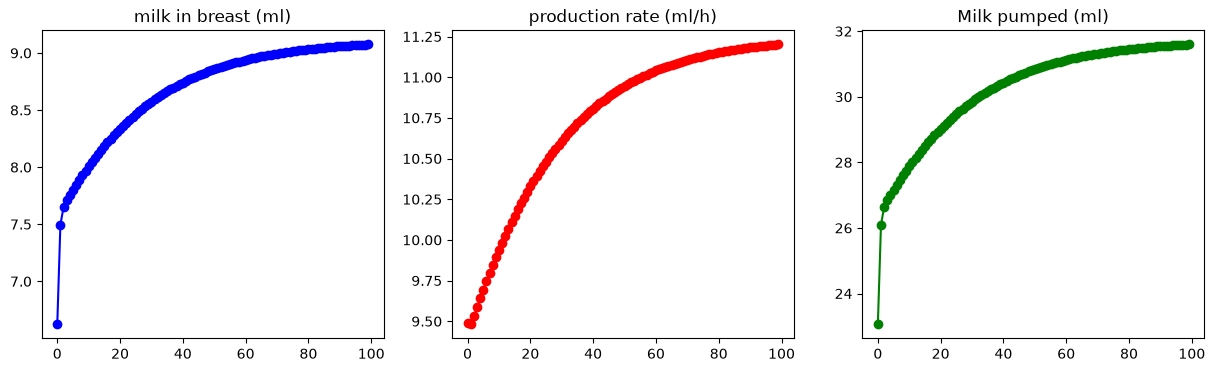

In [3]:
paras = {
    "delta": 0.05,
    "gamma": 0.1,
    "aMax": 30,
    "halfMax": 225,
    "nu": 3,
}

# initial data
m0=0
p0=10

nMax=100 # max iteration number
T=4 # wait interval
tau=0.5 #removal duration

# model specs
a_shape="concave"
a_arg="M"
h_shape="exponential"
protocol="set-duration"

# simulate
mFull, pFull, Mfull, T, tau =do_simulate_milk(m0, p0, T, tau, paras, nMax, a_shape, a_arg, h_shape,protocol)

# plot
fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # 1 row, 3 columns

axes[0].plot(range(len(mFull)),mFull,'-bo')
axes[0].set_title("milk in breast (ml)")
axes[1].plot(range(len(pFull)),pFull,'-ro')
axes[1].set_title("production rate (ml/h)")
axes[2].plot(range(len(Mfull)),Mfull,'-go')
axes[2].set_title("Milk pumped (ml)")

plt.show()


### Demo set-target protocol

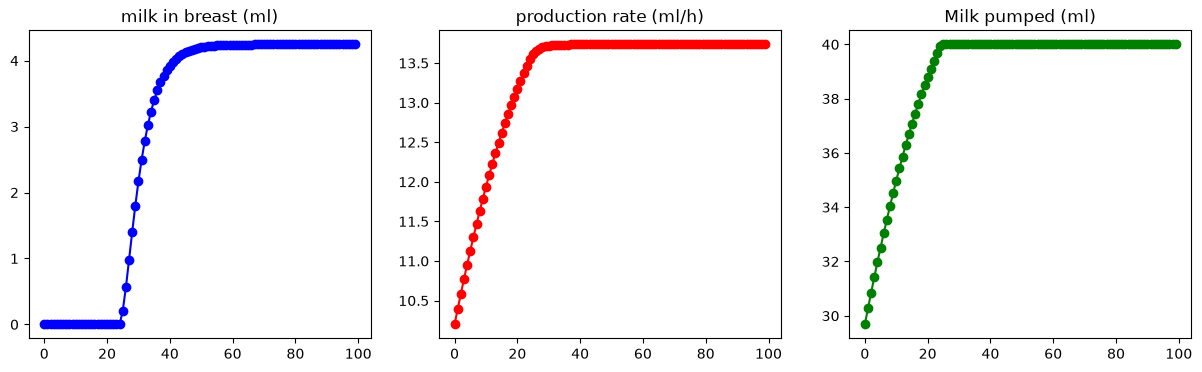

In [4]:
paras = {
    "delta": 0.05,
    "gamma": 0.1,
    "aMax": 30,
    "halfMax": 225,
    "nu": 3,
}

# initial data
m0=0
p0=10

nMax=100 # max iteration number
T=4 # wait interval
Mtar=40 # session target

# model specs
a_shape="concave"
a_arg="M"
h_shape="exponential"
protocol="set-target"

# simulate
mFull, pFull, Mfull, T, tau =do_simulate_milk(m0, p0, T, Mtar, paras, nMax, a_shape, a_arg, h_shape,protocol)

# plot
fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # 1 row, 3 columns

axes[0].plot(range(len(mFull)),mFull,'-bo')
axes[0].set_title("milk in breast (ml)")
axes[1].plot(range(len(pFull)),pFull,'-ro')
axes[1].set_title("production rate (ml/h)")
axes[2].plot(range(len(Mfull)),Mfull,'-go')
axes[2].set_title("Milk pumped (ml)")

plt.show()
